# 04 · Which LEMIS records should the model learn from?

**The question.** WildGuard's model learns from LEMIS and is applied to CITES, which covers CITES-listed species only. Most of LEMIS is not CITES-listed (notebook 03, X2). Should the model learn from every LEMIS line item, or only from the ones that look like CITES? This is the open decision on the training population in [`DATA/ALIGNING_LEMIS_AND_CITES.md`](../../DATA/ALIGNING_LEMIS_AND_CITES.md) §2.2.

**The method.** Train the same model on four candidate populations, changing nothing else, and test every candidate on **the same held-out records**: the ones most like CITES.

| Candidate | Learns from (training years 2000–2010) |
|---|---|
| **A** | every line item (the current pipeline) |
| **B** | animals with a class: drops rows without a class (mostly placeholder genera) and plants, fungi and bacteria |
| **C** | species with a CITES listing in force in the shipment year (species-level name match) |
| **C+** | C, plus line items whose genus had a CITES-listed species in force that year |

**Decision rule, fixed before any result was seen:**

1. **Evaluation set *E*:** LEMIS line items from the test years 2013–2014 whose species had a CITES listing in force in the shipment year. *E-commercial* is its commercial-purpose part.
2. **Primary metric:** recall at a 1% review budget, the share of *E*'s enforcement cases found in the top 1% of *E*'s records, ranked by each candidate's score.
3. **The rule:**
   - **C or C+ replaces B** only if its recall at 1% beats B's, with the 95% paired-bootstrap interval of the difference above zero, on *E* **and** on *E-commercial*. If both qualify, take the one with the higher recall on *E*.
   - **B replaces A** unless A beats B in the same way.

   The bootstrap resamples **shipments**, not line items, because line items of one shipment are not independent (notebook 01, L1 and L5).
4. **Reported but not deciding:**
   - average precision and recall at 5% on *E*;
   - recall at 1% per shipment;
   - every metric on all test-year records;
   - two CITES-side checks: how close each training population is to CITES, and how much the CITES top 1% changes between candidates.

**What is held fixed across candidates:**
- the year split (train 2000–2010, validate 2011–2012, test 2013–2014);
- the feature set (`SHARED_FEATURES`, the fields both datasets record), with peer norms and category vocabularies learned once from all training-year line items;
- the XGBoost settings of `wildguard/models.py`;
- early stopping on the same validation set, the validation-year line items with a species-level listing;
- three random seeds per candidate.

The comparison covers the **supervised model only**. The unsupervised detectors use no labels, so the training population does not reach them in the same way.

**One change from the current pipeline.** The `appendix` feature is the listing **in force in the shipment year**, ignoring Appendix N: the most recent appendix CITES recorded for the species (else its genus) in or before that year (notebook 03, X8). The pipeline's latest-year lookup would put listings from after 2014 onto 2000–2014 shipments.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import roc_auc_score

import eda_setup as E
import experiment_setup as X_
from wildguard.evaluate import evaluate_scores

E.style()
con = E.connect()


def Q(sql):
    return E.q(con, sql)


# NB04_SAMPLE < 1 runs a quick smoke test on a sample of shipments
SAMPLE = float(os.environ.get("NB04_SAMPLE", "1"))
SEEDS = (0, 1, 2) if SAMPLE == 1 else (0,)
N_BOOT = 1000 if SAMPLE == 1 else 50
BUDGET = 0.01
CANDIDATES = ["A", "B", "C", "C+"]
COLOURS = {"A": "#9b9a96", "B": E.LEMIS_C, "C": E.CITES_C, "C+": E.THIRD_C}
# which CITES records the CITES-side checks (section 6) score: Decision 1, notebook 05 (rule D)
CITES_RULE = "D"

## 1. Listing status in the shipment year

For each LEMIS species and shipment year, take the most recent appendix CITES recorded for that species **in or before** that year (Appendix N ignored; the strictest appendix when a year has several). The same is done for the genus, as a fallback. CITES records come from all years 1975–2026, so a listing is found as long as the species was ever traded under it before the shipment. The lookup, the year split, the features and the training procedure are shared with notebook 05 in [`experiment_setup.py`](experiment_setup.py).

In [2]:
df = X_.load_lemis(con, SAMPLE)
print(f"LEMIS line items: {len(df):,}")
level = np.select([df.sp_listed, df.gen_listed, df.animal],
                  ["species listed", "genus listed only", "animal, not matched"], "no class or not an animal")
df.assign(level=level).groupby("level").agg(
    line_items=("label", "size"), cases=("label", "sum"), case_rate=("label", "mean")
).sort_values("line_items", ascending=False).pipe(E.share, "line_items", "share")

LEMIS line items: 5,512,706


,line_items,cases,case_rate,share
level,,,,
"animal, not matched",2575651,31391,0.01219,46.72%
species listed,1385752,31743,0.02291,25.14%
genus listed only,1145716,26754,0.02335,20.78%
no class or not an animal,405587,5777,0.01424,7.36%


## 2. The candidate populations and the evaluation set

In [3]:
tr, va, te = X_.split(df)
animal, sp, gen = (df[c].to_numpy() for c in ("animal", "sp_listed", "gen_listed"))
commercial = (df["purpose"] == "T").to_numpy()

POP = {"A": tr, "B": tr & animal, "C": tr & sp, "C+": tr & gen}
VAL = va & sp                         # early stopping, the same for every candidate
EVAL = {"E": te & sp, "E-commercial": te & sp & commercial, "all test years": te}

y = df["label"].to_numpy()
rows = {f"train {k}": m for k, m in POP.items()} | {"validation (listed)": VAL} | EVAL
pd.DataFrame({"line_items": [m.sum() for m in rows.values()],
              "cases": [y[m].sum() for m in rows.values()],
              "case_rate": [y[m].mean() for m in rows.values()],
              "shipments": [df.loc[m, "shipment_id"].nunique() for m in rows.values()]},
             index=list(rows))

,line_items,cases,case_rate,shipments
train A,3877130,67149,0.01732,1493154
train B,3562032,63297,0.01777,1382934
train C,934559,22179,0.02373,397327
train C+,1789550,41476,0.02318,696924
validation (listed),216619,4820,0.02225,86298
E,234574,4744,0.02022,94147
E-commercial,183522,1901,0.01036,59276
all test years,822089,13062,0.01589,293689


Every candidate has tens of thousands of enforcement cases to learn from, so even the smallest population (C) is not short of data for a tree model. The case rate is higher among listed species, which is why each candidate must be tested on the same records: average precision rises with the base rate, so testing each model on its own population would favour whichever population has the easier mix.

In [4]:
t0 = time.time()
X, CATS = X_.build_features(df, tr)    # peer norms and category sets: all training years
ship = df["shipment_id"].to_numpy()
print(f"features for {len(X):,} line items ({time.time() - t0:.0f}s)")

features for 5,512,706 line items (33s)


## 3. Training

The same procedure as `wildguard.models.train_xgb` (class weight from the population's own case rate, early stopping on average precision), with the seed varied.

In [5]:
models, log = {}, []
for c in CANDIDATES:
    for seed in SEEDS:
        t = time.time()
        models[c, seed] = X_.fit(X, y, POP[c], VAL, seed)
        log.append({"candidate": c, "seed": seed, "train_rows": int(POP[c].sum()),
                    "best_iteration": models[c, seed].best_iteration,
                    "seconds": round(time.time() - t)})
        print(log[-1])
pd.DataFrame(log)

{'candidate': 'A', 'seed': 0, 'train_rows': 3877130, 'best_iteration': 153, 'seconds': 56}


{'candidate': 'A', 'seed': 1, 'train_rows': 3877130, 'best_iteration': 199, 'seconds': 69}


{'candidate': 'A', 'seed': 2, 'train_rows': 3877130, 'best_iteration': 176, 'seconds': 66}


{'candidate': 'B', 'seed': 0, 'train_rows': 3562032, 'best_iteration': 115, 'seconds': 31}


{'candidate': 'B', 'seed': 1, 'train_rows': 3562032, 'best_iteration': 178, 'seconds': 40}


...

{'candidate': 'C', 'seed': 2, 'train_rows': 934559, 'best_iteration': 101, 'seconds': 10}


{'candidate': 'C+', 'seed': 0, 'train_rows': 1789550, 'best_iteration': 90, 'seconds': 14}


{'candidate': 'C+', 'seed': 1, 'train_rows': 1789550, 'best_iteration': 72, 'seconds': 13}


{'candidate': 'C+', 'seed': 2, 'train_rows': 1789550, 'best_iteration': 165, 'seconds': 21}


,candidate,seed,train_rows,best_iteration,seconds
0,A,0,3877130,153,56
1,A,1,3877130,199,69
2,A,2,3877130,176,66
3,B,0,3562032,115,31
4,B,1,3562032,178,40
5,B,2,3562032,135,35
6,C,0,934559,102,10
7,C,1,934559,112,11
8,C,2,934559,101,10
9,C+,0,1789550,90,14


In [6]:
# each candidate's score: the mean of its three seeds' probabilities, on every test-year row
S_te = {c: np.mean([models[c, s].predict_proba(X[te])[:, 1] for s in SEEDS], axis=0)
        for c in CANDIDATES}
S_seed = {(c, s): models[c, s].predict_proba(X[te])[:, 1] for c in CANDIDATES for s in SEEDS}
y_te, ship_te = y[te], ship[te]
sub = {k: m[te] for k, m in EVAL.items()}      # evaluation sets as masks within the test years

## 4. Results on the evaluation set

In [7]:
def metrics(yy, ss):
    m = evaluate_scores(yy, ss, 0.5)
    return {"recall@1%": m["recall@1%"], "recall@5%": m["recall@5%"],
            "precision@1%": m["precision@1%"], "avg_precision": m["pr_auc"]}


def shipment_recall(c, mask):
    g = pd.DataFrame({"s": ship_te[mask], "y": y_te[mask], "p": S_te[c][mask]}).groupby("s").max()
    return metrics(g["y"].to_numpy(), g["p"].to_numpy())["recall@1%"]


res = {}
for c in CANDIDATES:
    for k, m in sub.items():
        for name, v in metrics(y_te[m], S_te[c][m]).items():
            res[(k, name), c] = v
    res[("E", "shipment recall@1%"), c] = shipment_recall(c, sub["E"])
table = pd.Series(res).unstack()[CANDIDATES]
table.index = pd.MultiIndex.from_tuples(table.index, names=["evaluated on", "metric"])
table.sort_index().style.format("{:.4f}").highlight_max(axis=1, props="font-weight: bold")

**Seed spread.** Recall at 1% on *E* for each seed separately. If seeds of one candidate differ by as much as the candidates do, no single run should be trusted:

In [8]:
spread = pd.DataFrame({c: [metrics(y_te[sub["E"]], S_seed[c, s][sub["E"]])["recall@1%"]
                           for s in SEEDS] for c in CANDIDATES}, index=[f"seed {s}" for s in SEEDS])
spread.loc["range"] = spread.max() - spread.min()
spread.style.format("{:.4f}")

,A,B,C,C+
seed 0,0.4127,0.4138,0.4125,0.4193
seed 1,0.4157,0.4167,0.4142,0.4110
seed 2,0.4157,0.4203,0.4113,0.4153
range,0.0030,0.0065,0.0030,0.0082


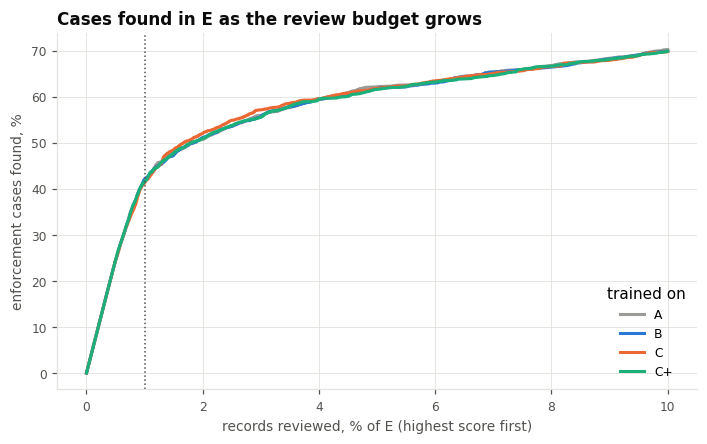

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
m = sub["E"]
for c in CANDIDATES:
    s = S_te[c][m]
    o = np.argsort(-s, kind="stable")
    caught = np.cumsum(y_te[m][o]) / y_te[m].sum()
    frac = np.arange(1, len(o) + 1) / len(o)
    k = frac <= 0.10
    ax.plot(frac[k] * 100, caught[k] * 100, color=COLOURS[c], lw=2, label=c)
ax.axvline(BUDGET * 100, color=E.INK_2, lw=1, ls=":")
ax.set_xlabel("records reviewed, % of E (highest score first)")
ax.set_ylabel("enforcement cases found, %")
ax.set_title("Cases found in E as the review budget grows", loc="left")
ax.legend(title="trained on", frameon=False)
plt.show()

## 5. Applying the decision rule

Paired bootstrap: each of 1,000 resamples draws *E*'s shipments with replacement, and every candidate is scored on the same resample. The table gives each candidate's recall at 1% minus the comparison candidate's, with its 95% interval.

In [10]:
def weighted_recall_at(order, yy, w, budget=BUDGET):
    ws = w[order]
    top = np.cumsum(ws) <= budget * ws.sum()
    return (ws[top] * yy[order][top]).sum() / (w * yy).sum()


def bootstrap(mask, seed=37):
    codes, uniq = pd.factorize(ship_te[mask])
    yy = y_te[mask]
    orders = {c: np.argsort(-S_te[c][mask], kind="stable") for c in CANDIDATES}
    rng = np.random.default_rng(seed)
    out = {c: np.empty(N_BOOT) for c in CANDIDATES}
    for b in range(N_BOOT):
        w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes].astype(float)
        for c in CANDIDATES:
            out[c][b] = weighted_recall_at(orders[c], yy, w)
    return out


boot = {k: bootstrap(sub[k]) for k in ("E", "E-commercial")}
rows = []
for k, bs in boot.items():
    for c, ref in (("C", "B"), ("C+", "B"), ("A", "B"), ("C", "C+")):
        d = bs[c] - bs[ref]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append({"evaluated on": k, "comparison": f"{c} − {ref}", "difference": d.mean(),
                     "95% low": lo, "95% high": hi,
                     "verdict": "higher" if lo > 0 else "lower" if hi < 0 else "no clear difference"})
ci = pd.DataFrame(rows)
ci.style.format({"difference": "{:+.4f}", "95% low": "{:+.4f}", "95% high": "{:+.4f}"})

,evaluated on,comparison,difference,95% low,95% high,verdict
0,E,C − B,-0.0065,-0.0126,+0.0000,no clear difference
1,E,C+ − B,-0.0043,-0.0091,+0.0012,no clear difference
2,E,A − B,-0.0050,-0.0091,+0.0006,no clear difference
3,E,C − C+,-0.0022,-0.0075,+0.0031,no clear difference
4,E-commercial,C − B,+0.0185,+0.0053,+0.0327,higher
5,E-commercial,C+ − B,-0.0014,-0.0110,+0.0077,no clear difference
6,E-commercial,A − B,+0.0017,-0.0058,+0.0093,no clear difference
7,E-commercial,C − C+,+0.0199,+0.0088,+0.0317,higher


In [11]:
def beats(c, ref):
    return all(((ci["evaluated on"] == k) & (ci["comparison"] == f"{c} − {ref}")
                & (ci["95% low"] > 0)).any() for k in ("E", "E-commercial"))


base = "A" if beats("A", "B") else "B"
qualify = [c for c in ("C", "C+") if base == "B" and beats(c, "B")]
winner = max(qualify, key=lambda c: table.loc[("E", "recall@1%"), c]) if qualify else base
print(f"A clearly better than B on both sets: {beats('A', 'B')}")
for c in ("C", "C+"):
    print(f"{c} clearly better than B on both sets: {beats(c, 'B')}")
print(f"\nDecision under the pre-stated rule: train on population {winner}")

A clearly better than B on both sets: False
C clearly better than B on both sets: False
C+ clearly better than B on both sets: False

Decision under the pre-stated rule: train on population B


## 6. Checks on CITES itself

CITES has no labels, so these checks cannot pick a winner. They show whether the choice matters where the model is deployed.

**Does the CITES top 1% change?** Each candidate's top 1% of CITES records in each year, and the share of it that another candidate's top 1% also contains. Both lists have the same length, so the table is symmetric. 100% would mean the choice of training population makes no difference to what a reviewer sees.

**CITES records used:** 2015–2024, chosen by the mirror-record rule of Decision 1 (notebook 05, rule D): exporter-reported records plus importer-reported records with no exact exporter counterpart. Appendix N, source `I` and purpose `L` removed ([`ALIGNING`](../../DATA/ALIGNING_LEMIS_AND_CITES.md) §1.2). The aligned CITES file still writes pre-Convention as `O` and reintroduction as `N`, so those codes are mapped to LEMIS's `P` and `Y` before scoring (ALIGNING §2.1). Otherwise every candidate would see an unknown code. The features are the pipeline's CITES features, with peer norms learned from CITES.

In [12]:
cites, Xc = X_.load_cites(CATS, keep=X_.queue_rids(con, CITES_RULE))
cy = cites["year"].to_numpy()
SC = {c: np.mean([models[c, s].predict_proba(Xc)[:, 1] for s in SEEDS], axis=0) for c in CANDIDATES}
print(f"CITES records scored: {len(Xc):,} (mirror-record rule {CITES_RULE})")
TOP = {c: X_.top_within_year(SC[c], cy, BUDGET) for c in CANDIDATES}
# both lists have the same length, so the share is the same read either way
overlap = pd.DataFrame({c: {r: (TOP[c] & TOP[r]).sum() / TOP[c].sum() for r in CANDIDATES}
                        for c in CANDIDATES})
overlap.style.format("{:.1%}")

CITES records scored: 5,465,917 (mirror-record rule D)


,A,B,C,C+
A,100.0%,77.0%,77.0%,79.2%
B,77.0%,100.0%,66.1%,65.4%
C,77.0%,66.1%,100.0%,81.7%
C+,79.2%,65.4%,81.7%,100.0%


**How close is each training population to CITES?** A classifier is trained to tell a population's records from CITES records, using only raw, directly comparable fields, the same fields as `wildguard.domain_shift`. An AUC of 0.5 means the classifier cannot tell them apart; 1.0 means it always can.

In [13]:
RAW_COMPARABLE = ["class", "product_group", "unit_group", "purpose", "source", "appendix",
                  "origin_region", "exporter_region", "genus_top", "exporter_top", "origin_top",
                  "log_qty", "reexport_flag", "is_wild"]


def domain_auc(Xa, Xb, n=250_000, seed=37):
    rng = np.random.default_rng(seed)
    ia = rng.choice(len(Xa), min(len(Xa), n), replace=False)
    ib = rng.choice(len(Xb), min(len(Xb), n), replace=False)
    Z = pd.concat([Xa.iloc[ia], Xb.iloc[ib]], ignore_index=True)
    d = np.r_[np.zeros(len(ia)), np.ones(len(ib))]
    p = rng.permutation(len(Z))
    cut = int(0.7 * len(Z))
    clf = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist",
                            enable_categorical=True, subsample=0.8, colsample_bytree=0.8,
                            n_jobs=8, random_state=seed)
    clf.fit(Z.iloc[p[:cut]], d[p[:cut]])
    return roc_auc_score(d[p[cut:]], clf.predict_proba(Z.iloc[p[cut:]])[:, 1])


Xc_raw = Xc[RAW_COMPARABLE]
pd.Series({c: domain_auc(X.loc[POP[c], RAW_COMPARABLE], Xc_raw) for c in CANDIDATES},
          name="AUC: training population vs CITES").to_frame().style.format("{:.3f}")

,AUC: training population vs CITES
A,0.988
B,0.987
C,0.961
C+,0.975


## What this means for Decision 2

| # | Finding | What it means for Decision 2 |
|---|---|---|
| P1 | **On CITES-listed test records (*E*), the four candidates are indistinguishable.** Recall at 1% is 0.413–0.421; every paired difference has a 95% interval that includes zero. The gaps between candidates are about the size of the spread between seeds of one candidate (up to 0.008) | Dropping the unlisted half of LEMIS neither helps nor hurts on CITES-listed species overall. The model already separates listed from unlisted records through the features (appendix, genus, class) |
| P2 | **On the commercial part of *E*, C is better.** Recall at 1%: C 0.273 vs B 0.254 (+0.019, interval +0.005 to +0.033); C also beats C+ (+0.020). A and C+ do no better than B | CITES is 90% commercial (C6), so this is the part of *E* most like deployment. Commercial listed trade is where a model trained only on listed species learns something the others miss |
| P3 | **On all test-year records, C is much worse** (recall at 1%: 0.343 vs B 0.469, A 0.489) | Expected and irrelevant to deployment: C never sees unlisted taxa, and CITES never contains them. It is a reminder that C's model is specialised and must not be used to score LEMIS-wide |
| P4 | **The choice changes what a CITES reviewer sees.** On the records chosen by the Decision 1 rule (notebook 05, rule D), the top 1% per year under B and C share only 66.1%; A and B share 77.0% | Similar LEMIS metrics do not mean similar CITES queues: about a third of the records reviewed first depend on this decision |
| P5 | **No training population is close to CITES.** Domain-classifier AUC against the rule-D CITES records: A 0.988, B 0.987, C+ 0.975, C 0.961 | Restricting to listed species narrows the shift only slightly. The shift comes mostly from other differences (routes, quantities, product mix; notebook 03, X10), so the population choice is not a fix for it |

**Under the pre-stated rule the decision is B** (animals with a class). A does no better than B, and neither C nor C+ beats B on both *E* and *E-commercial*. C beats B on *E-commercial* only.

**What the rule does not settle.** P2 and P4 together point to a real trade-off:
- B is as good as anything on listed species overall, and keeps the most data.
- C is better on listed commercial trade, which is most of what CITES contains.
- The two give noticeably different CITES review queues.

Changing the rule now, for example to make *E-commercial* the primary set, would be choosing the test after seeing the result. If commercial performance is what matters most for WildGuard, that should be stated as a design principle and tested again (for example on a different split), not adopted from this run alone.

**Limits of this experiment:**
- *E* is US import declarations of CITES-listed species, a stand-in for CITES, not CITES itself.
- Listing status comes from name matching against CITES records, so synonyms are missed (X2).
- Only the supervised model was compared; the hybrid adds unsupervised scores on top.